# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import AveragePooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


True

# Importamos los datos

In [4]:
path = '../../../data/clean/Campo 50 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')
campvectrain = np.transpose(campvectrain, (0,2,3,1))

In [6]:
np.shape(campvectrain)

(7000, 50, 50, 2)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')
campvectest = np.transpose(campvectest, (0,2,3,1))

In [10]:
np.shape(campvectest)

(1000, 50, 50, 2)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(1000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')
campvecval = np.transpose(campvecval, (0,2,3,1))

In [14]:
np.shape(campvecval)

(2000, 50, 50, 2)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(2000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(50, 50, 2), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [20]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [21]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [22]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [23]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

In [24]:
import optuna
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l1, l2

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(scheduler)

def objective(trial):
    model = Sequential()
    n_conv_layers = trial.suggest_int("n_conv_layers", 1, 3)
    
    input_shape = (50, 50, 2)  # Tus dimensiones de entrada
    current_shape = input_shape
    
    for i in range(n_conv_layers):
        num_filters = trial.suggest_int(f"num_filters_{i+1}", 8, 64)
        filter_size1 = trial.suggest_int(f"filter_size1_{i+1}", 2, 5)
        filter_size2 = trial.suggest_int(f"filter_size2_{i+1}", 2, 5)
        activation = trial.suggest_categorical(f"activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"kernel_regularizer_{i+1}", ['l1', 'l2'])
        
        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)
            
            
        if (current_shape[0] - filter_size1 + 1 > 0) and (current_shape[1] - filter_size2 + 1 > 0):
            if i == 0:
                model.add(Conv2D(num_filters, (filter_size1, filter_size2), activation=activation, input_shape=input_shape, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
            else:
                model.add(Conv2D(num_filters, (filter_size1, filter_size2), activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
            
            current_shape = (current_shape[0] - filter_size1 + 1, current_shape[1] - filter_size2 + 1, num_filters)
            
        # Decide si agregar una capa de MaxPooling después de esta capa convolucional
        add_maxpooling = trial.suggest_categorical(f"add_maxpooling_after_conv_{i+1}", [True, False])
        if add_maxpooling:
            if current_shape[0] >= 2 and current_shape[1] >= 2:  # Asegurarse de que ambas dimensiones son suficientes para MaxPooling
                model.add(MaxPooling2D(pool_size=(2, 2)))
                current_shape = (current_shape[0] // 2, current_shape[1] // 2, current_shape[2])
        
    model.add(Flatten())
    n_dense_layers = trial.suggest_int("n_dense_layers", 1, 4)
    
    for i in range(n_dense_layers):
        num_units = trial.suggest_int(f"num_units_{i+1}", 16, 128)
        activation = trial.suggest_categorical(f"dense_activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"dense_kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"dense_kernel_regularizer_{i+1}", ['l1', 'l2'])

        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)

        model.add(Dense(num_units, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
    
        # Decide si agregar una capa de Dropout después de esta capa densa
        add_dropout = trial.suggest_categorical(f"add_dropout_after_dense_{i+1}", [True, False])
        if add_dropout:
            dropout_rate = trial.suggest_float(f"dropout_rate_after_dense_{i+1}", 0.1, 0.5)
            model.add(Dropout(dropout_rate))
            
    model.add(Dense(7, activation=custom_activation))
        
    optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
        
    model.compile(optimizer=optimizer, loss= 'mean_squared_error', metrics=metrics)
    
    history = model.fit(
        train_dataset, 
        validation_data=val_dataset, 
        epochs=20,  
        callbacks=[reduce_lr, early_stop]
    )
    
    val_mean_metric = history.history['val_mean_metric'][-1]
    
    return val_mean_metric

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=300)

print(f'Número de trials finalizados: {len(study.trials)}')
print(f'Mejor trial:')
trial = study.best_trial

print(f'  Valor: {trial.value}')
print('  Parámetros: ')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

C:\Users\rafae\anaconda3\envs\tfgpu\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2023-10-23 09:39:45,259] A new study created in memory with name: no-name-d8d438d2-74f7-44cb-8382-4c13f9c125da


Epoch 1/20
70/70 [==============================] - 3s 32ms/step - loss: 10.6525 - a_1: 2.5495 - a_2: 2.5648 - b_1: 2.1859 - b_2: 2.3466 - d_1: 1.6310 - d_2: 1.6051 - n: 1.3558 - mean_metric: 0.4447 - val_loss: 7.3241 - val_a_1: 2.3521 - val_a_2: 2.4382 - val_b_1: 1.3773 - val_b_2: 1.6639 - val_d_1: 1.2354 - val_d_2: 1.3317 - val_n: 1.2471 - val_mean_metric: 0.3614 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 2s 29ms/step - loss: 6.8212 - a_1: 2.1353 - a_2: 2.4679 - b_1: 1.4561 - b_2: 1.5832 - d_1: 1.2615 - d_2: 1.2703 - n: 1.2704 - mean_metric: 0.3575 - val_loss: 5.7762 - val_a_1: 1.8319 - val_a_2: 2.3424 - val_b_1: 1.4304 - val_b_2: 1.3217 - val_d_1: 0.9821 - val_d_2: 1.1003 - val_n: 1.2169 - val_mean_metric: 0.3173 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 2s 29ms/step - loss: 5.7899 - a_1: 1.6291 - a_2: 2.2749 - b_1: 1.3740 - b_2: 1.4557 - d_1: 1.2287 - d_2: 1.2030 - n: 1.2290 - mean_metric: 0.3247 - val_loss: 4.7263 - val_a_1: 1.4212 - va

[I 2023-10-23 09:40:27,780] Trial 0 finished with value: 0.22602446377277374 and parameters: {'n_conv_layers': 2, 'num_filters_1': 51, 'filter_size1_1': 2, 'filter_size2_1': 4, 'activation_1': 'relu', 'kernel_initializer_1': 'HeNormal', 'kernel_regularizer_1': 'l2', 'add_maxpooling_after_conv_1': False, 'num_filters_2': 54, 'filter_size1_2': 4, 'filter_size2_2': 4, 'activation_2': 'tanh', 'kernel_initializer_2': 'HeNormal', 'kernel_regularizer_2': 'l1', 'add_maxpooling_after_conv_2': True, 'n_dense_layers': 3, 'num_units_1': 19, 'dense_activation_1': 'relu', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l1', 'add_dropout_after_dense_1': False, 'num_units_2': 41, 'dense_activation_2': 'sigmoid', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': True, 'dropout_rate_after_dense_2': 0.20891089328402399, 'num_units_3': 86, 'dense_activation_3': 'relu', 'dense_kernel_initializer_3': 'HeNormal', 'dense_ke

Epoch 1/20
70/70 [==============================] - 2s 20ms/step - loss: 9.3305 - a_1: 2.5027 - a_2: 2.5043 - b_1: 2.6750 - b_2: 2.4861 - d_1: 1.7743 - d_2: 1.9520 - n: 1.2822 - mean_metric: 0.4740 - val_loss: 6.9071 - val_a_1: 2.4938 - val_a_2: 2.4564 - val_b_1: 2.4623 - val_b_2: 2.0482 - val_d_1: 1.2416 - val_d_2: 1.2850 - val_n: 1.2372 - val_mean_metric: 0.4104 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 17ms/step - loss: 6.2015 - a_1: 2.4986 - a_2: 2.5047 - b_1: 2.0292 - b_2: 1.7958 - d_1: 1.3067 - d_2: 1.3162 - n: 1.2678 - mean_metric: 0.3973 - val_loss: 4.9971 - val_a_1: 2.5088 - val_a_2: 2.4570 - val_b_1: 1.6043 - val_b_2: 1.2829 - val_d_1: 1.0308 - val_d_2: 0.9926 - val_n: 1.2316 - val_mean_metric: 0.3447 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 17ms/step - loss: 5.1690 - a_1: 2.4921 - a_2: 2.4953 - b_1: 1.5131 - b_2: 1.4719 - d_1: 1.2102 - d_2: 1.1915 - n: 1.2566 - mean_metric: 0.3633 - val_loss: 4.5299 - val_a_1: 2.4897 - val

[I 2023-10-23 09:40:52,397] Trial 1 finished with value: 0.1181810200214386 and parameters: {'n_conv_layers': 3, 'num_filters_1': 18, 'filter_size1_1': 2, 'filter_size2_1': 2, 'activation_1': 'tanh', 'kernel_initializer_1': 'glorot_uniform', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': False, 'num_filters_2': 26, 'filter_size1_2': 4, 'filter_size2_2': 2, 'activation_2': 'tanh', 'kernel_initializer_2': 'glorot_uniform', 'kernel_regularizer_2': 'l2', 'add_maxpooling_after_conv_2': True, 'num_filters_3': 29, 'filter_size1_3': 4, 'filter_size2_3': 3, 'activation_3': 'tanh', 'kernel_initializer_3': 'random_normal', 'kernel_regularizer_3': 'l1', 'add_maxpooling_after_conv_3': False, 'n_dense_layers': 4, 'num_units_1': 111, 'dense_activation_1': 'sigmoid', 'dense_kernel_initializer_1': 'random_normal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.13273174278548444, 'num_units_2': 89, 'dense_activation_2': 'sigmoid', 'de

Epoch 1/20
70/70 [==============================] - 2s 16ms/step - loss: 17.5014 - a_1: 2.5600 - a_2: 2.5668 - b_1: 2.7764 - b_2: 2.6787 - d_1: 1.7008 - d_2: 1.6155 - n: 1.4054 - mean_metric: 0.4780 - val_loss: 14.4915 - val_a_1: 2.4850 - val_a_2: 2.4810 - val_b_1: 2.5982 - val_b_2: 2.5074 - val_d_1: 1.0324 - val_d_2: 1.1061 - val_n: 1.2597 - val_mean_metric: 0.4180 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 13ms/step - loss: 13.8831 - a_1: 2.5308 - a_2: 2.5330 - b_1: 2.6805 - b_2: 2.4721 - d_1: 1.2274 - d_2: 1.2611 - n: 1.2837 - mean_metric: 0.4370 - val_loss: 12.6000 - val_a_1: 2.4987 - val_a_2: 2.4817 - val_b_1: 2.5732 - val_b_2: 2.3003 - val_d_1: 1.0177 - val_d_2: 1.2922 - val_n: 1.2680 - val_mean_metric: 0.4168 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 13ms/step - loss: 11.8911 - a_1: 2.4970 - a_2: 2.5251 - b_1: 2.6020 - b_2: 1.9406 - d_1: 1.2369 - d_2: 1.2936 - n: 1.2754 - mean_metric: 0.4177 - val_loss: 10.4960 - val_a_1: 2.4702

... (592 outputs left out)

[I 2023-10-23 11:36:49,874] Trial 298 finished with value: 0.05301902815699577 and parameters: {'n_conv_layers': 3, 'num_filters_1': 27, 'filter_size1_1': 4, 'filter_size2_1': 5, 'activation_1': 'relu', 'kernel_initializer_1': 'random_normal', 'kernel_regularizer_1': 'l2', 'add_maxpooling_after_conv_1': False, 'num_filters_2': 13, 'filter_size1_2': 2, 'filter_size2_2': 4, 'activation_2': 'tanh', 'kernel_initializer_2': 'random_normal', 'kernel_regularizer_2': 'l1', 'add_maxpooling_after_conv_2': True, 'num_filters_3': 32, 'filter_size1_3': 3, 'filter_size2_3': 4, 'activation_3': 'tanh', 'kernel_initializer_3': 'HeNormal', 'kernel_regularizer_3': 'l1', 'add_maxpooling_after_conv_3': False, 'n_dense_layers': 2, 'num_units_1': 107, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': False, 'num_units_2': 107, 'dense_activation_2': 'relu', 'dense_kernel_initializer_2': 'glorot_uniform', 'dense_kernel_regul

Epoch 1/20
70/70 [==============================] - 2s 16ms/step - loss: 5.0625 - a_1: 2.3505 - a_2: 2.4662 - b_1: 1.7966 - b_2: 1.9281 - d_1: 1.0518 - d_2: 1.1420 - n: 1.2496 - mean_metric: 0.3744 - val_loss: 3.1974 - val_a_1: 1.8915 - val_a_2: 2.3387 - val_b_1: 0.9886 - val_b_2: 1.0712 - val_d_1: 0.6484 - val_d_2: 0.8613 - val_n: 1.2082 - val_mean_metric: 0.2795 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 13ms/step - loss: 2.1324 - a_1: 1.2187 - a_2: 1.6775 - b_1: 0.8838 - b_2: 0.8750 - d_1: 0.5867 - d_2: 0.5829 - n: 1.1525 - mean_metric: 0.2179 - val_loss: 1.4811 - val_a_1: 0.9342 - val_a_2: 1.0024 - val_b_1: 0.7002 - val_b_2: 0.7354 - val_d_1: 0.5418 - val_d_2: 0.7208 - val_n: 1.1123 - val_mean_metric: 0.1783 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 13ms/step - loss: 1.3102 - a_1: 0.8053 - a_2: 0.9209 - b_1: 0.6610 - b_2: 0.6884 - d_1: 0.4591 - d_2: 0.4673 - n: 1.1025 - mean_metric: 0.1594 - val_loss: 1.0952 - val_a_1: 0.6553 - val

[I 2023-10-23 11:37:10,527] Trial 299 finished with value: 0.04095298424363136 and parameters: {'n_conv_layers': 3, 'num_filters_1': 26, 'filter_size1_1': 4, 'filter_size2_1': 5, 'activation_1': 'relu', 'kernel_initializer_1': 'random_normal', 'kernel_regularizer_1': 'l2', 'add_maxpooling_after_conv_1': True, 'num_filters_2': 56, 'filter_size1_2': 2, 'filter_size2_2': 4, 'activation_2': 'tanh', 'kernel_initializer_2': 'random_normal', 'kernel_regularizer_2': 'l2', 'add_maxpooling_after_conv_2': True, 'num_filters_3': 46, 'filter_size1_3': 3, 'filter_size2_3': 4, 'activation_3': 'relu', 'kernel_initializer_3': 'HeNormal', 'kernel_regularizer_3': 'l2', 'add_maxpooling_after_conv_3': True, 'n_dense_layers': 2, 'num_units_1': 111, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': False, 'num_units_2': 112, 'dense_activation_2': 'sigmoid', 'dense_kernel_initializer_2': 'glorot_uniform', 'dense_kernel_regu

Número de trials finalizados: 300
Mejor trial:
  Valor: 0.039673835039138794
  Parámetros: 
    n_conv_layers: 3
    num_filters_1: 16
    filter_size1_1: 4
    filter_size2_1: 5
    activation_1: relu
    kernel_initializer_1: random_normal
    kernel_regularizer_1: l2
    add_maxpooling_after_conv_1: False
    num_filters_2: 42
    filter_size1_2: 2
    filter_size2_2: 4
    activation_2: tanh
    kernel_initializer_2: random_normal
    kernel_regularizer_2: l2
    add_maxpooling_after_conv_2: True
    num_filters_3: 51
    filter_size1_3: 3
    filter_size2_3: 4
    activation_3: tanh
    kernel_initializer_3: HeNormal
    kernel_regularizer_3: l2
    add_maxpooling_after_conv_3: True
    n_dense_layers: 2
    num_units_1: 108
    dense_activation_1: tanh
    dense_kernel_initializer_1: HeNormal
    dense_kernel_regularizer_1: l2
    add_dropout_after_dense_1: False
    num_units_2: 105
    dense_activation_2: relu
    dense_kernel_initializer_2: glorot_uniform
    dense_kernel_regu

In [24]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.regularizers import l1, l2

# Initialize the model
model = Sequential()

# Add Convolutional Layers
# Conv Layer 1
model.add(Conv2D(filters=18, kernel_size=(5, 5), activation='tanh', input_shape = (50,50,2), kernel_initializer='glorot_uniform', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D())  # MaxPooling after Conv Layer 1

# Conv Layer 2
model.add(Conv2D(filters=53, kernel_size=(5, 2), activation='relu', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

# Conv Layer 3
model.add(Conv2D(filters=19, kernel_size=(4, 5), activation='tanh', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D())  # MaxPooling after Conv Layer 3

# Flatten before passing to Dense Layers
model.add(Flatten())

# Add Dense Layers
# Dense Layer 1
model.add(Dense(113, activation='relu', kernel_initializer='he_normal', kernel_regularizer=l2(0.001)))
model.add(Dense(7, activation=custom_activation))


# Show the model architecture
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 46, 46, 18)        918       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 23, 23, 18)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 19, 22, 53)        9593      
                                                                 
 conv2d_2 (Conv2D)           (None, 16, 18, 19)        20159     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 8, 9, 19)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 1368)              0

In [25]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.regularizers import l1, l2

# Iniciar el modelo
model = Sequential()

# Input shape (Asumo que es el mismo que antes: (50, 10, 2))

# Primera capa convolucional
model.add(Conv2D(16, (4, 5), activation='relu', input_shape=(50, 50, 2), kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))

# Segunda capa convolucional
model.add(Conv2D(42, (2, 4), activation='tanh', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))  # Añadir MaxPooling de tamaño 2x2

# Tercera capa convolucional
model.add(Conv2D(51, (3, 4), activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))  # Añadir MaxPooling de tamaño 2x2

# Aplanar para capas densas
model.add(Flatten())

# Primera capa densa
model.add(Dense(108, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))

# Segunda capa densa
model.add(Dense(105, activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))


model.add(Dense(7, activation=custom_activation))

# Resumen del modelo para verificar la arquitectura
# model.summary()


In [26]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 47, 46, 16)        656       
                                                                 
 conv2d_4 (Conv2D)           (None, 46, 43, 42)        5418      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 23, 21, 42)       0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 21, 18, 51)        25755     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 10, 9, 51)        0         
 2D)                                                             
                                                                 
 flatten_1 (Flatten)         (None, 4590)             

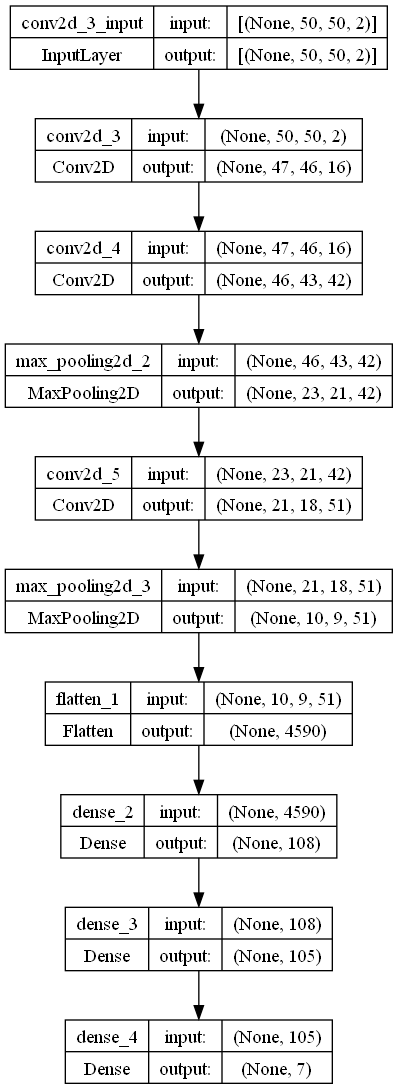

In [27]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [28]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [29]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [30]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [31]:
model.compile(optimizer=optimizer,
              loss= 'mean_squared_error',
              metrics=metrics)

In [32]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166



def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 200
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch

In [33]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 2s 22ms/step - loss: 6.4393 - a_1: 2.5195 - a_2: 2.5195 - b_1: 2.2941 - b_2: 1.8324 - d_1: 1.0776 - d_2: 1.0430 - n: 1.2994 - mean_metric: 0.3930 - val_loss: 4.8370 - val_a_1: 2.4308 - val_a_2: 2.5238 - val_b_1: 1.3812 - val_b_2: 1.0051 - val_d_1: 0.6943 - val_d_2: 0.8461 - val_n: 1.2689 - val_mean_metric: 0.3149 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 1s 18ms/step - loss: 4.4363 - a_1: 2.3089 - a_2: 2.4634 - b_1: 1.0379 - b_2: 0.9903 - d_1: 0.6906 - d_2: 0.7062 - n: 1.2330 - mean_metric: 0.2946 - val_loss: 3.7813 - val_a_1: 1.9680 - val_a_2: 2.3555 - val_b_1: 0.7933 - val_b_2: 0.8419 - val_d_1: 0.5360 - val_d_2: 0.5254 - val_n: 1.2220 - val_mean_metric: 0.2558 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 1s 18ms/step - loss: 3.1696 - a_1: 1.3867 - a_2: 1.9463 - b_1: 0.8497 - b_2: 0.8563 - d_1: 0.6032 - d_2: 0.5853 - n: 1.1855 - mean_metric: 0.2315 - val_loss: 2.4026 - val_a_1: 1.0549

70/70 [==============================] - 1s 18ms/step - loss: 0.3463 - a_1: 0.2140 - a_2: 0.1925 - b_1: 0.2330 - b_2: 0.2238 - d_1: 0.1893 - d_2: 0.1911 - n: 0.1161 - mean_metric: 0.0425 - val_loss: 0.3341 - val_a_1: 0.1685 - val_a_2: 0.1776 - val_b_1: 0.2300 - val_b_2: 0.2068 - val_d_1: 0.1615 - val_d_2: 0.1831 - val_n: 0.1235 - val_mean_metric: 0.0388 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.3373 - a_1: 0.2157 - a_2: 0.2148 - b_1: 0.2076 - b_2: 0.2286 - d_1: 0.1592 - d_2: 0.1797 - n: 0.1309 - mean_metric: 0.0417 - val_loss: 0.3228 - val_a_1: 0.1988 - val_a_2: 0.2017 - val_b_1: 0.1562 - val_b_2: 0.1759 - val_d_1: 0.1363 - val_d_2: 0.1733 - val_n: 0.1289 - val_mean_metric: 0.0363 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.3377 - a_1: 0.2383 - a_2: 0.2301 - b_1: 0.2198 - b_2: 0.2091 - d_1: 0.1809 - d_2: 0.2017 - n: 0.1378 - mean_metric: 0.0443 - val_loss: 0.3197 - val_a_1: 0.2025 - val_a_2:

70/70 [==============================] - 1s 19ms/step - loss: 0.1901 - a_1: 0.1794 - a_2: 0.1660 - b_1: 0.2134 - b_2: 0.1818 - d_1: 0.1613 - d_2: 0.1658 - n: 0.1031 - mean_metric: 0.0366 - val_loss: 0.1981 - val_a_1: 0.1880 - val_a_2: 0.1749 - val_b_1: 0.2425 - val_b_2: 0.2599 - val_d_1: 0.1784 - val_d_2: 0.1568 - val_n: 0.1065 - val_mean_metric: 0.0406 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.2405 - a_1: 0.2960 - a_2: 0.2635 - b_1: 0.3137 - b_2: 0.2758 - d_1: 0.2215 - d_2: 0.2176 - n: 0.1215 - mean_metric: 0.0534 - val_loss: 0.2095 - val_a_1: 0.2372 - val_a_2: 0.2386 - val_b_1: 0.2304 - val_b_2: 0.2225 - val_d_1: 0.2057 - val_d_2: 0.1566 - val_n: 0.1436 - val_mean_metric: 0.0445 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 1s 19ms/step - loss: 0.2099 - a_1: 0.2043 - a_2: 0.2159 - b_1: 0.2539 - b_2: 0.2478 - d_1: 0.1931 - d_2: 0.2027 - n: 0.1075 - mean_metric: 0.0445 - val_loss: 0.1960 - val_a_1: 0.1880 - val_a_2:

70/70 [==============================] - 1s 18ms/step - loss: 0.1401 - a_1: 0.1585 - a_2: 0.1515 - b_1: 0.1687 - b_2: 0.1762 - d_1: 0.1307 - d_2: 0.1429 - n: 0.0834 - mean_metric: 0.0316 - val_loss: 0.1385 - val_a_1: 0.2393 - val_a_2: 0.1399 - val_b_1: 0.1441 - val_b_2: 0.1427 - val_d_1: 0.0984 - val_d_2: 0.1187 - val_n: 0.0788 - val_mean_metric: 0.0298 - lr: 0.0010
Epoch 128/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.1312 - a_1: 0.1390 - a_2: 0.1327 - b_1: 0.1405 - b_2: 0.1581 - d_1: 0.1032 - d_2: 0.1223 - n: 0.0761 - mean_metric: 0.0272 - val_loss: 0.1325 - val_a_1: 0.1516 - val_a_2: 0.1480 - val_b_1: 0.1698 - val_b_2: 0.1796 - val_d_1: 0.1026 - val_d_2: 0.1090 - val_n: 0.0764 - val_mean_metric: 0.0291 - lr: 0.0010
Epoch 129/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.1481 - a_1: 0.1848 - a_2: 0.1552 - b_1: 0.2187 - b_2: 0.1939 - d_1: 0.1585 - d_2: 0.1635 - n: 0.0951 - mean_metric: 0.0365 - val_loss: 0.1479 - val_a_1: 0.1749 - val_a_

70/70 [==============================] - 1s 19ms/step - loss: 0.1156 - a_1: 0.1612 - a_2: 0.1518 - b_1: 0.1780 - b_2: 0.1575 - d_1: 0.1446 - d_2: 0.1751 - n: 0.0926 - mean_metric: 0.0332 - val_loss: 0.1174 - val_a_1: 0.1384 - val_a_2: 0.1413 - val_b_1: 0.1542 - val_b_2: 0.1441 - val_d_1: 0.1773 - val_d_2: 0.2574 - val_n: 0.0750 - val_mean_metric: 0.0338 - lr: 0.0010
Epoch 170/1000
70/70 [==============================] - 1s 19ms/step - loss: 0.1230 - a_1: 0.1652 - a_2: 0.1609 - b_1: 0.1981 - b_2: 0.2059 - d_1: 0.1644 - d_2: 0.1820 - n: 0.0879 - mean_metric: 0.0364 - val_loss: 0.1323 - val_a_1: 0.1349 - val_a_2: 0.1698 - val_b_1: 0.2786 - val_b_2: 0.3133 - val_d_1: 0.1310 - val_d_2: 0.1437 - val_n: 0.0806 - val_mean_metric: 0.0388 - lr: 0.0010
Epoch 171/1000
70/70 [==============================] - 1s 19ms/step - loss: 0.1214 - a_1: 0.1453 - a_2: 0.1721 - b_1: 0.2171 - b_2: 0.2089 - d_1: 0.1491 - d_2: 0.1577 - n: 0.0842 - mean_metric: 0.0354 - val_loss: 0.1180 - val_a_1: 0.1320 - val_a_

70/70 [==============================] - 1s 18ms/step - loss: 0.1185 - a_1: 0.1482 - a_2: 0.1715 - b_1: 0.1970 - b_2: 0.1834 - d_1: 0.1296 - d_2: 0.1500 - n: 0.0856 - mean_metric: 0.0333 - val_loss: 0.1168 - val_a_1: 0.1637 - val_a_2: 0.2055 - val_b_1: 0.1428 - val_b_2: 0.1335 - val_d_1: 0.1176 - val_d_2: 0.2007 - val_n: 0.0742 - val_mean_metric: 0.0322 - lr: 9.8762e-04
Epoch 212/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.1108 - a_1: 0.1438 - a_2: 0.1468 - b_1: 0.1596 - b_2: 0.1746 - d_1: 0.1232 - d_2: 0.1475 - n: 0.0722 - mean_metric: 0.0302 - val_loss: 0.1028 - val_a_1: 0.1459 - val_a_2: 0.1183 - val_b_1: 0.1346 - val_b_2: 0.1310 - val_d_1: 0.1078 - val_d_2: 0.1306 - val_n: 0.0700 - val_mean_metric: 0.0260 - lr: 9.8639e-04
Epoch 213/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.1055 - a_1: 0.1452 - a_2: 0.1294 - b_1: 0.1548 - b_2: 0.1436 - d_1: 0.1142 - d_2: 0.1482 - n: 0.0720 - mean_metric: 0.0283 - val_loss: 0.1042 - val_a_1: 0.1389 

... (2 outputs left out)

70/70 [==============================] - 1s 18ms/step - loss: 0.0731 - a_1: 0.1527 - a_2: 0.1194 - b_1: 0.1457 - b_2: 0.1500 - d_1: 0.1185 - d_2: 0.1184 - n: 0.0628 - mean_metric: 0.0271 - val_loss: 0.0653 - val_a_1: 0.1096 - val_a_2: 0.1455 - val_b_1: 0.0969 - val_b_2: 0.1304 - val_d_1: 0.0909 - val_d_2: 0.1069 - val_n: 0.0553 - val_mean_metric: 0.0228 - lr: 8.3170e-04
Epoch 338/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.0692 - a_1: 0.1282 - a_2: 0.1204 - b_1: 0.1336 - b_2: 0.1429 - d_1: 0.1025 - d_2: 0.1141 - n: 0.0616 - mean_metric: 0.0251 - val_loss: 0.0663 - val_a_1: 0.1564 - val_a_2: 0.1032 - val_b_1: 0.1054 - val_b_2: 0.1159 - val_d_1: 0.1117 - val_d_2: 0.0812 - val_n: 0.0659 - val_mean_metric: 0.0229 - lr: 8.3046e-04
Epoch 339/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.0689 - a_1: 0.1317 - a_2: 0.1133 - b_1: 0.1400 - b_2: 0.1505 - d_1: 0.0990 - d_2: 0.1131 - n: 0.0534 - mean_metric: 0.0250 - val_loss: 0.0678 - val_a_1: 0.0988 

70/70 [==============================] - 1s 18ms/step - loss: 0.0658 - a_1: 0.1126 - a_2: 0.1280 - b_1: 0.1474 - b_2: 0.1369 - d_1: 0.1284 - d_2: 0.1187 - n: 0.0574 - mean_metric: 0.0259 - val_loss: 0.0734 - val_a_1: 0.1195 - val_a_2: 0.1341 - val_b_1: 0.1871 - val_b_2: 0.1433 - val_d_1: 0.1410 - val_d_2: 0.1932 - val_n: 0.0640 - val_mean_metric: 0.0305 - lr: 7.7972e-04
Epoch 380/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.0804 - a_1: 0.1607 - a_2: 0.1460 - b_1: 0.1439 - b_2: 0.2082 - d_1: 0.1210 - d_2: 0.1670 - n: 0.0782 - mean_metric: 0.0320 - val_loss: 0.0714 - val_a_1: 0.1559 - val_a_2: 0.1498 - val_b_1: 0.1283 - val_b_2: 0.1757 - val_d_1: 0.1088 - val_d_2: 0.1011 - val_n: 0.0743 - val_mean_metric: 0.0277 - lr: 7.7849e-04
Epoch 381/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.0637 - a_1: 0.1430 - a_2: 0.1124 - b_1: 0.1228 - b_2: 0.1274 - d_1: 0.1039 - d_2: 0.1056 - n: 0.0612 - mean_metric: 0.0242 - val_loss: 0.0573 - val_a_1: 0.1238 

70/70 [==============================] - 1s 19ms/step - loss: 0.1486 - a_1: 0.1518 - a_2: 0.2172 - b_1: 0.1861 - b_2: 0.2018 - d_1: 0.1604 - d_2: 0.1433 - n: 0.0766 - mean_metric: 0.0355 - val_loss: 0.1382 - val_a_1: 0.1336 - val_a_2: 0.1703 - val_b_1: 0.2084 - val_b_2: 0.1547 - val_d_1: 0.1595 - val_d_2: 0.1460 - val_n: 0.0639 - val_mean_metric: 0.0322 - lr: 7.2775e-04
Epoch 422/1000
70/70 [==============================] - 1s 19ms/step - loss: 0.1389 - a_1: 0.1523 - a_2: 0.1813 - b_1: 0.1873 - b_2: 0.1726 - d_1: 0.1570 - d_2: 0.1353 - n: 0.0707 - mean_metric: 0.0330 - val_loss: 0.1283 - val_a_1: 0.1402 - val_a_2: 0.1441 - val_b_1: 0.1332 - val_b_2: 0.1575 - val_d_1: 0.1708 - val_d_2: 0.0933 - val_n: 0.0670 - val_mean_metric: 0.0281 - lr: 7.2651e-04
Epoch 423/1000
70/70 [==============================] - 1s 19ms/step - loss: 0.1414 - a_1: 0.1789 - a_2: 0.2185 - b_1: 0.1867 - b_2: 0.1756 - d_1: 0.1453 - d_2: 0.1325 - n: 0.0823 - mean_metric: 0.0350 - val_loss: 0.1616 - val_a_1: 0.3026 

70/70 [==============================] - 1s 18ms/step - loss: 0.0690 - a_1: 0.0995 - a_2: 0.1178 - b_1: 0.1269 - b_2: 0.1303 - d_1: 0.1178 - d_2: 0.0895 - n: 0.0538 - mean_metric: 0.0230 - val_loss: 0.0641 - val_a_1: 0.0894 - val_a_2: 0.1064 - val_b_1: 0.0995 - val_b_2: 0.1060 - val_d_1: 0.0925 - val_d_2: 0.0717 - val_n: 0.0581 - val_mean_metric: 0.0194 - lr: 6.7577e-04
Epoch 464/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.0704 - a_1: 0.1265 - a_2: 0.1405 - b_1: 0.1278 - b_2: 0.1165 - d_1: 0.1076 - d_2: 0.0988 - n: 0.0584 - mean_metric: 0.0242 - val_loss: 0.0690 - val_a_1: 0.0979 - val_a_2: 0.1152 - val_b_1: 0.1438 - val_b_2: 0.1102 - val_d_1: 0.1077 - val_d_2: 0.1204 - val_n: 0.0550 - val_mean_metric: 0.0233 - lr: 6.7454e-04
Epoch 465/1000
70/70 [==============================] - 1s 18ms/step - loss: 0.0753 - a_1: 0.1411 - a_2: 0.1383 - b_1: 0.1498 - b_2: 0.1299 - d_1: 0.1341 - d_2: 0.1122 - n: 0.0627 - mean_metric: 0.0271 - val_loss: 0.0826 - val_a_1: 0.1593 

# Analizamos accuracy y loss

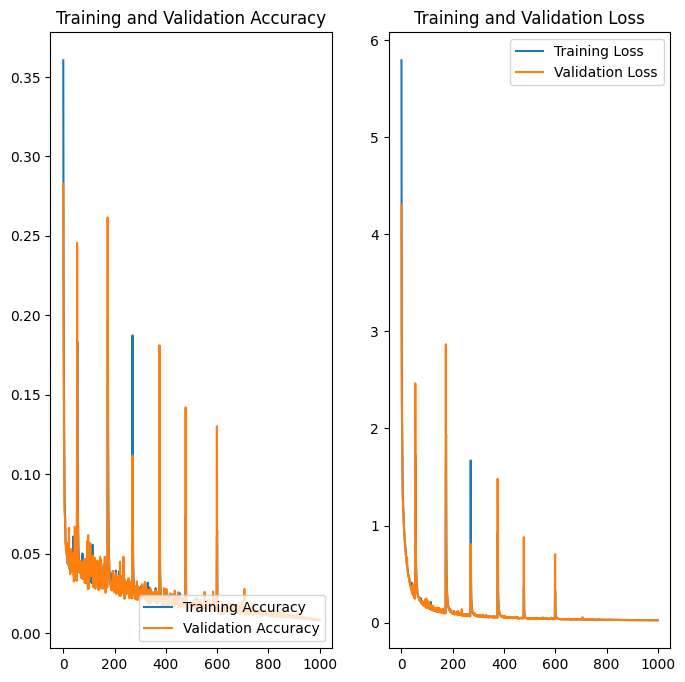

In [70]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(1000)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

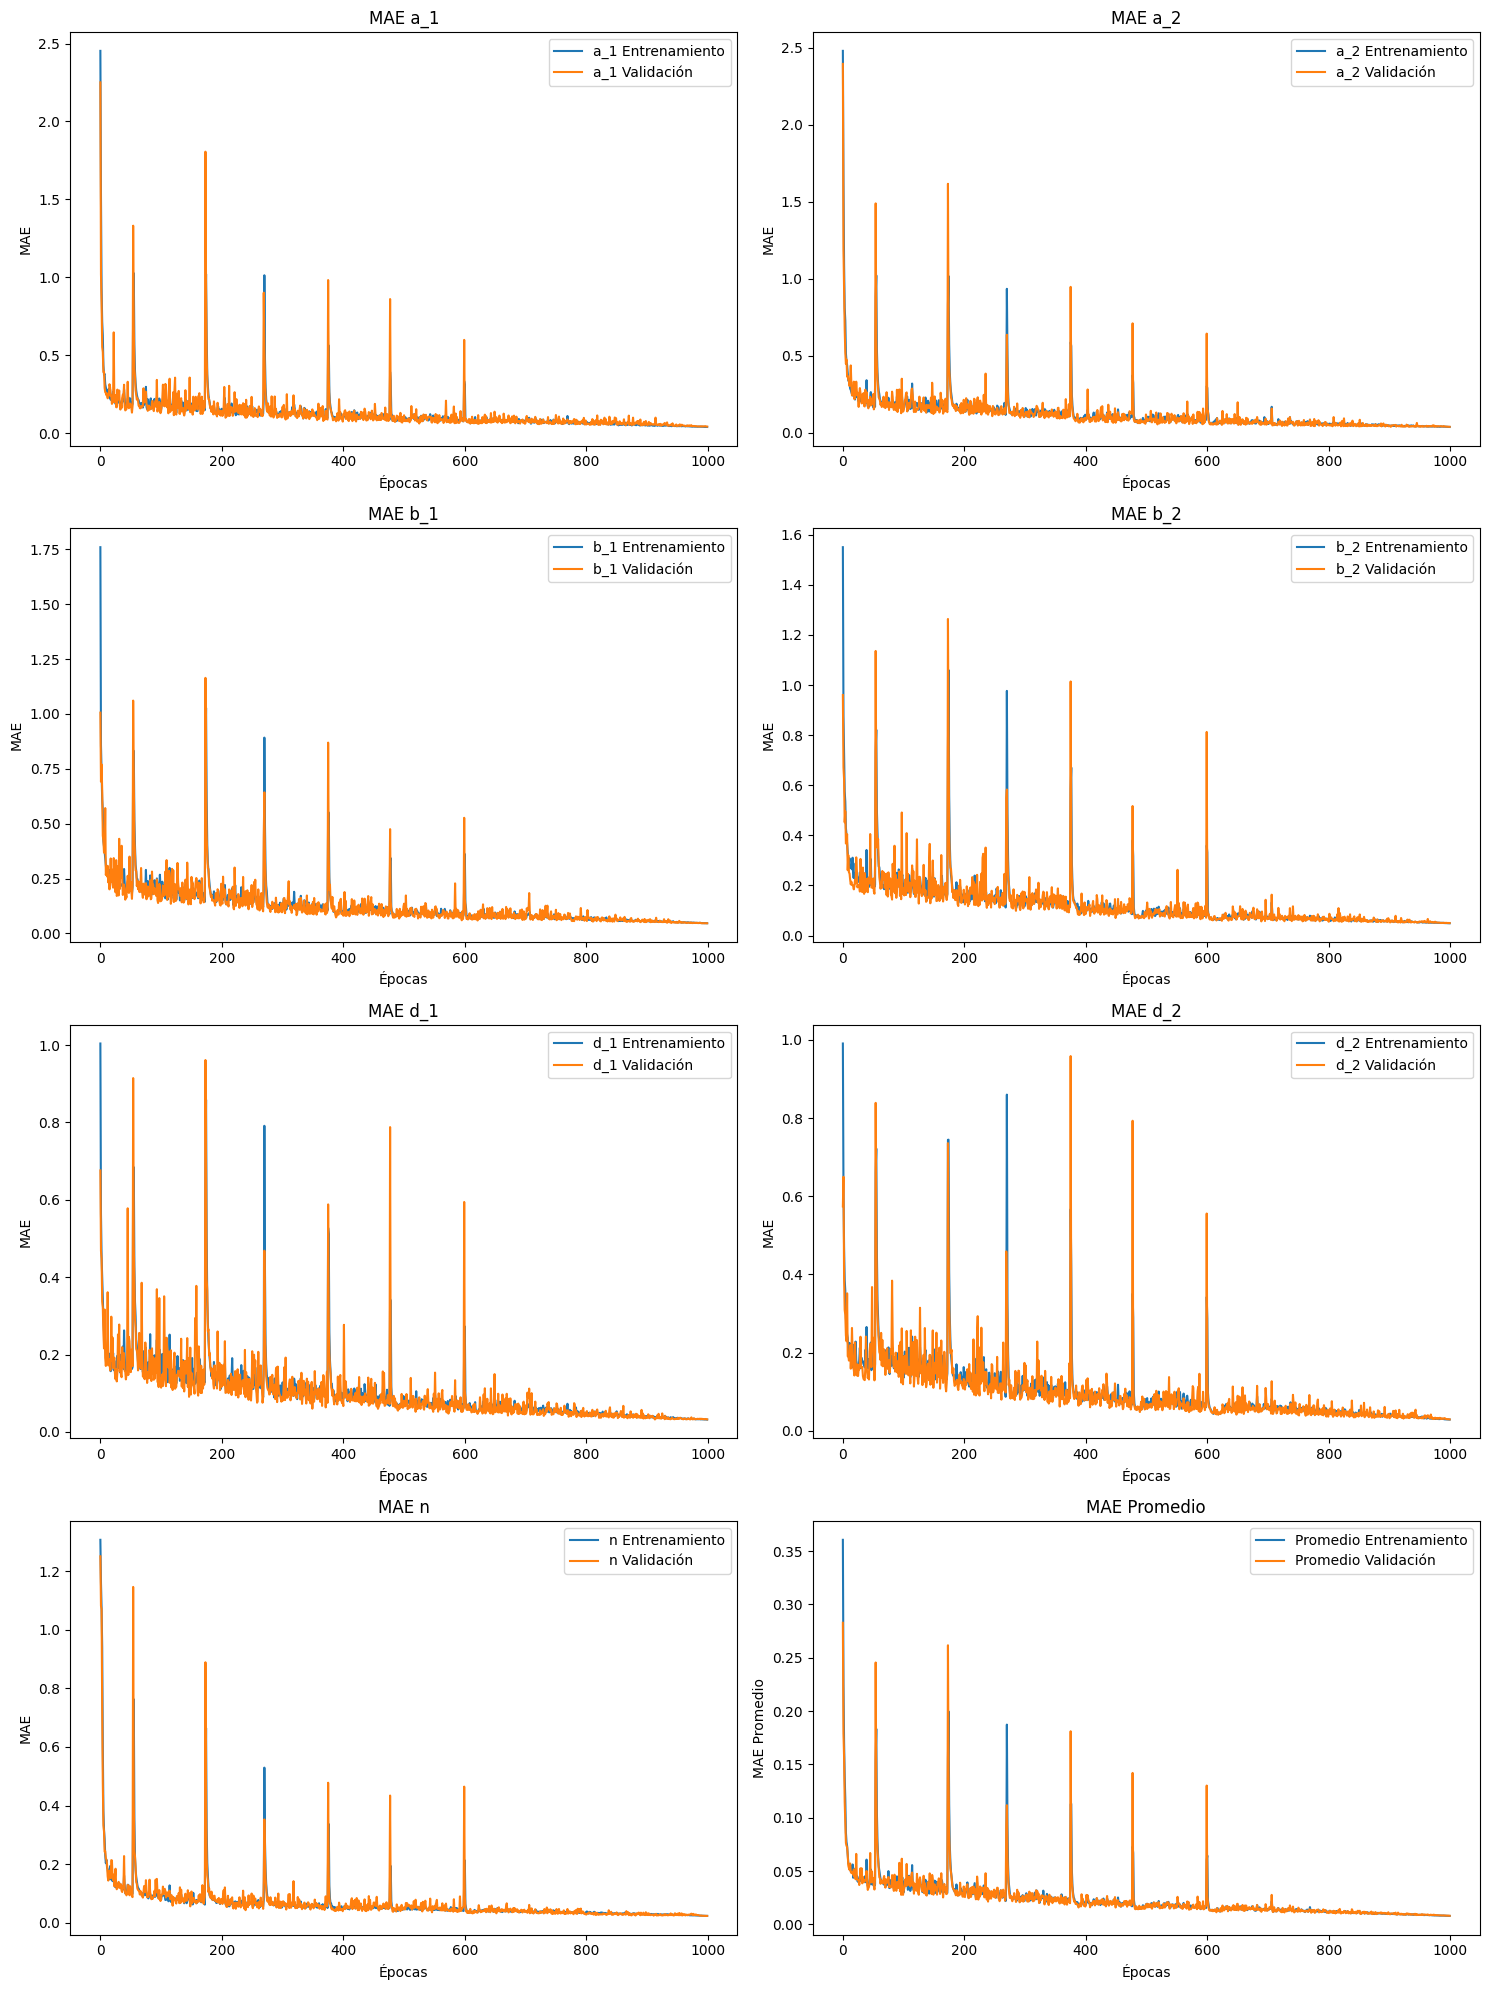

In [71]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [43]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

32/32 [==============================] - 0s 4ms/step - loss: 0.0252 - a_1: 0.0447 - a_2: 0.0362 - b_1: 0.0490 - b_2: 0.0501 - d_1: 0.0320 - d_2: 0.0265 - n: 0.0229 - mean_metric: 0.0081


In [44]:
predictions = model.predict(campvectest)

32/32 [==============================] - 0s 2ms/step


In [45]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[ 9  7  6  7  0 10  4]
[9.0975275  6.9342556  6.0124183  6.994728   0.05087084 9.893256
 4.0032682 ]
[43 41 36 50 24 32 36 37 20 41 27 33 42 32 43 39 36 28 20 45 29 36 46 31
 37 36 33 32 19 23 20 41 35 29 38 32 37 42 36 30 27 33 38 40 24 30 41 36
 38 36 30 29 48 40 40 31 27 38 35 30 36 33 23 44 38 24 22 38 35 18 33 33
 26 40 42 26 51 48 42 32 44 35 27 32 37 35 32 27 34 23 30 31 38 37 24 24
 23 30 36 45 32 28 40 23 34 29 29 29 35 35 32 46 31 35 33 45 33 32 30 34
 36 45 31 28 40 35 36 41 39 32 37 36 27 29 27 14 29 42 29 22 35 39 30 39
 35 38 42 28 15 41 18 34 28 23 36 38 46 30 34 29 30 32 20 39 33 35 41 29
 29 41 22 26 30 25 40 42 35 26 26 30 29 37 31 44 34 37 40 33 34 25 42 25
 37 43 40 35 32 34 37 35 27 25 27 41 25 29 29 33 50 29 41 30 35 36 34 27
 42 27 32 36 30 22 51 33 20 41 40 12 21 34 35 23 28 38 34 33 34 40 24 18
 31 26 24 34 39 35 43 33 32 36 46 41 29 34 50 23 31 35 37 28 29 42 39 27
 32 42 34 38 34 41 43 27 42 25 22 41 61 30 36 20 38 29 42 34 34 30 31 23
 36 34 35 34 39 47 49 2

0.04883499762841633

In [46]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.03718714954065425, Desviación estándar del error: 0.053777814688232506, Error absoluto máximo: 0.4147965908050537


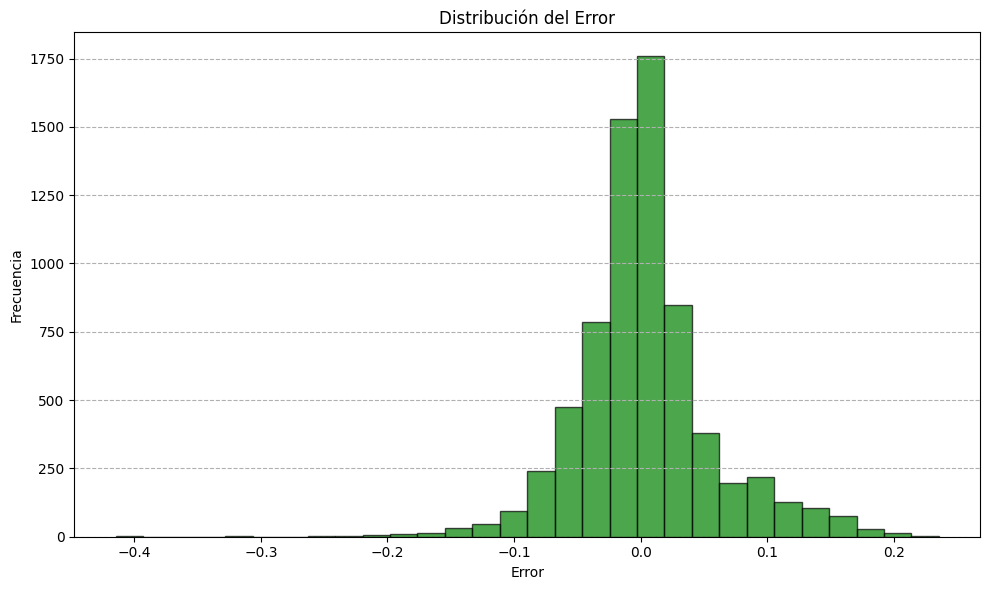

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [48]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.008095586169705776
Desviación estándar del error relativo: 0.0046009868699978754
Error absoluto máximo relativo: 0.02540179491043091


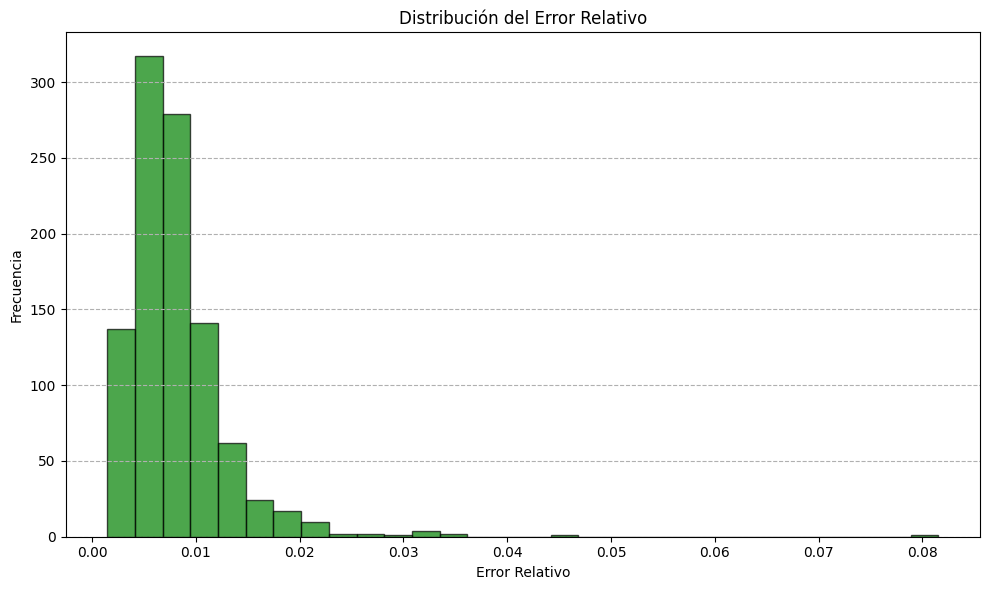

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

# Guardamos los datos de Accuracy y Loss

In [50]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales/grid50_traj100/historyconvcampvec50.csv', index=False)

# Guardamos el modelo

In [51]:
path_to_save = '../../../trained_models_clean/grid50_traj100/'

In [52]:
model.save(path_to_save + '/convolucionalcv50.h5')

# Importamos el modelo

In [35]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [36]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [37]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_clean/grid50_traj100/convolucionalcv50.h5', custom_objects=custom_objects)

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [42]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos =10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[9, 5, 4, 10, 4, 9, 0]


In [43]:
campvecnone = campvec[None, :]
campvecnone = np.transpose(campvecnone, (0,2,3,1))

## Predecimos con los datos nuevos

In [44]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 16ms/step
[[ 1.  1.  8. 10.  4.  9.  2.]]


## Encontramos puntos de equilibrio datos reales

In [45]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b2
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(2.125, 1.3888888888888888)


## Graficamos con los coeficientes reales

Text(0, 0.5, 'Concentración Y')

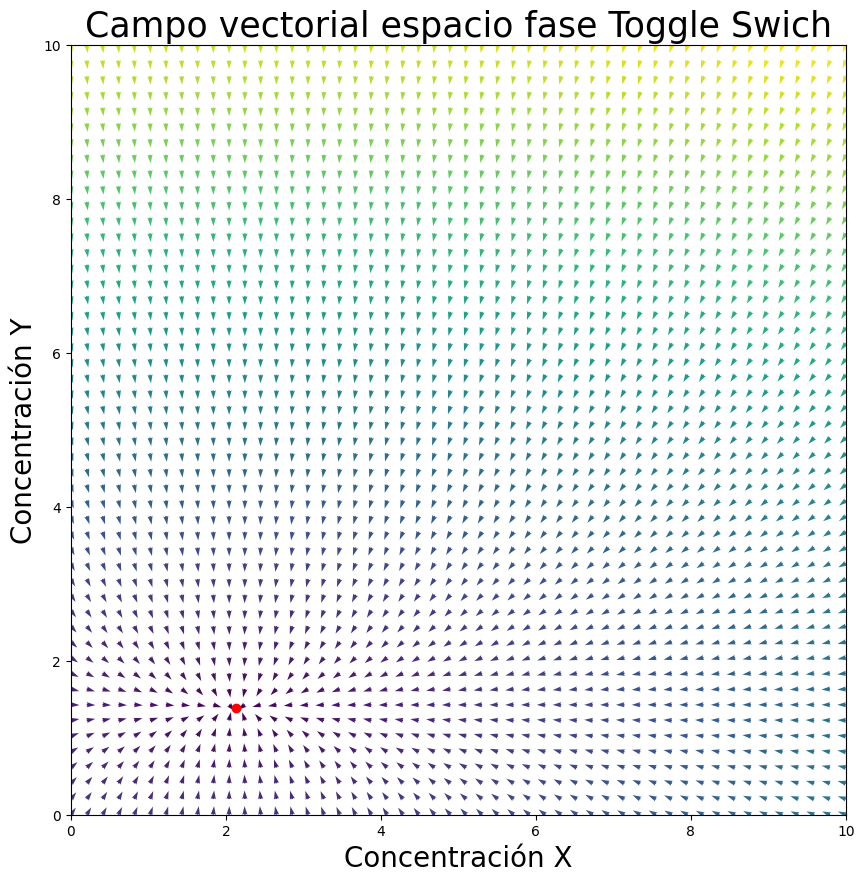

In [50]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 50)
y2 = np.linspace(0, 10, 50)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=25)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X', fontsize=20)
plt.ylabel('Concentración Y', fontsize = 20)

## Encontramos puntos de equilibro datos predecidos

In [47]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b2pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(2.109635464803212, 1.1314963696046725)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

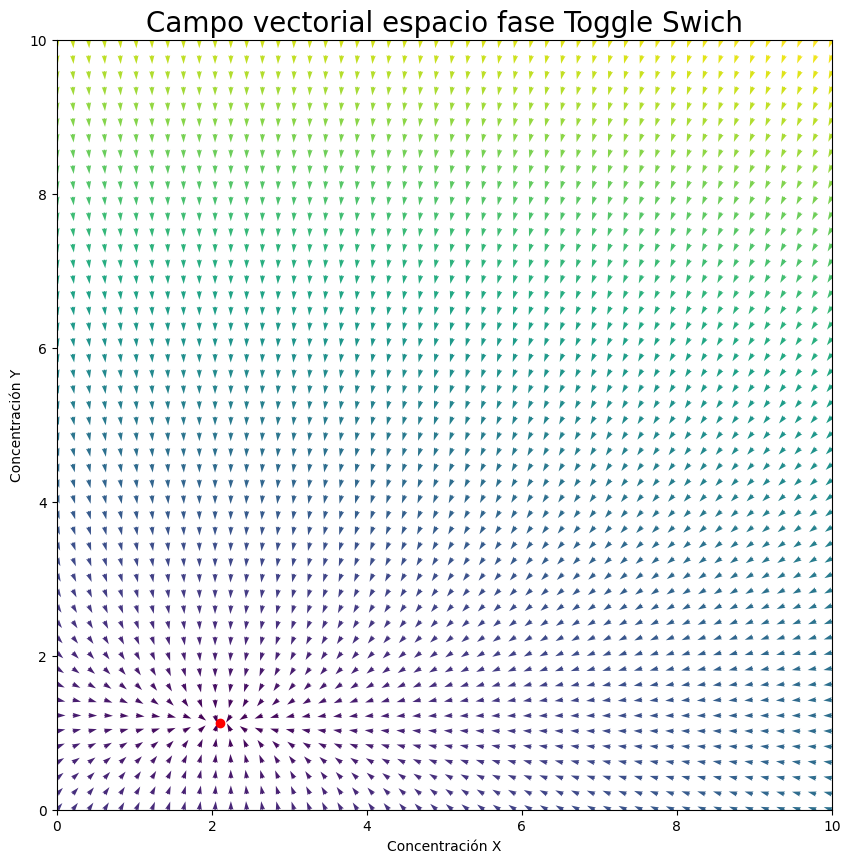

In [48]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 50)
y2pred = np.linspace(y_range_neg, y_range_pos, 50)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

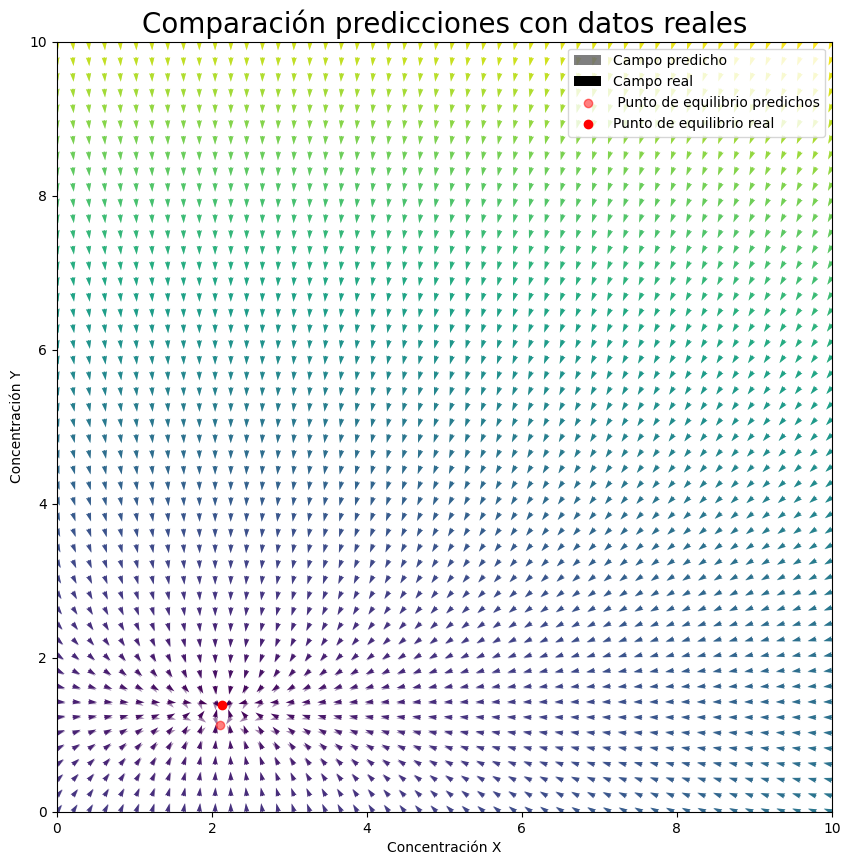

In [49]:
#%matplotlib qt
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5, label = "Campo predicho")

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1, label = "Campo real")

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5, label = " Punto de equilibrio predichos")
ax.scatter(x_values, y_values, color='red', alpha = 1, label = "Punto de equilibrio real")
ax.set_title('Comparación predicciones con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')
ax.legend(loc='upper right')  # Agregar leyenda a la gráfica
plt.show()

## Graficamos las diferencias

0.0


C:\Users\rafae\anaconda3\envs\tfgpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
C:\Users\rafae\anaconda3\envs\tfgpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


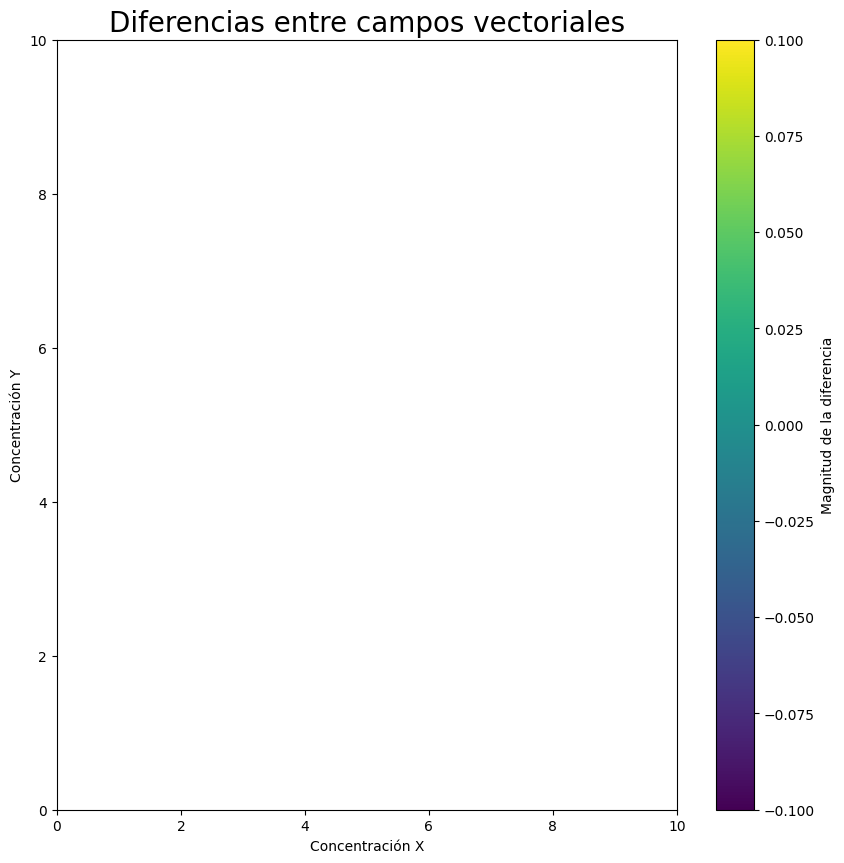

In [64]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores realativos

C:\Users\rafae\anaconda3\envs\tfgpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
C:\Users\rafae\anaconda3\envs\tfgpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


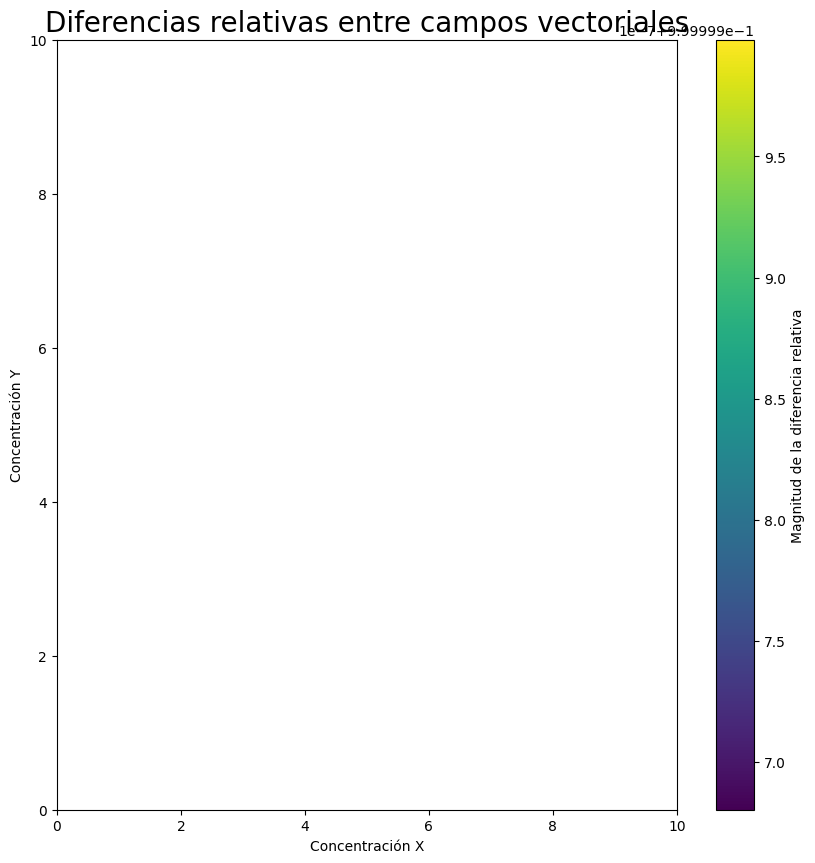

In [65]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [66]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 0.9999999982248582
El valor de u1 en el error relativo máximo es: -49.99009900990099
El valor de u1pred en el error relativo máximo es: -49.99009900990099
El valor de v1 en el error relativo máximo es: -25.97029702970297
El valor de v1pred en el error relativo máximo es: -25.97029702970297


In [67]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 0.00%


## Hacemos esto n veces

In [68]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    campvecnone = np.transpose(campvecnone, (0,2,3,1))
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 50)
    y2pred = np.linspace(y_range_neg, y_range_pos, 50)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred

 # Calculamos las diferencias
    u_diff = u - upred
    v_diff = v - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 36.28%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 4.76%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 0.00%
--------------------------------------------
1/1 [=============================

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 4.32%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 8.92%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 15.60%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de punto

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 18.96%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 1.36%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de 

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 265 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 266 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 267 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 268 es 6.84%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 269 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de p

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 353 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 354 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 355 es 5.76%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 356 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 357 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de p

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 441 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 442 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 443 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 444 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 445 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de p

... (208 outputs left out)

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9818 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9819 es 10.20%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9820 es 15.80%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9821 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9822 es 3.32%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcenta

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9862 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9863 es 7.80%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9864 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9865 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9866 es 2.32%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9906 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9907 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9908 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9909 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9910 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9950 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9951 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9952 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9953 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9954 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje

El promedio de los porcentajes es 4.58%


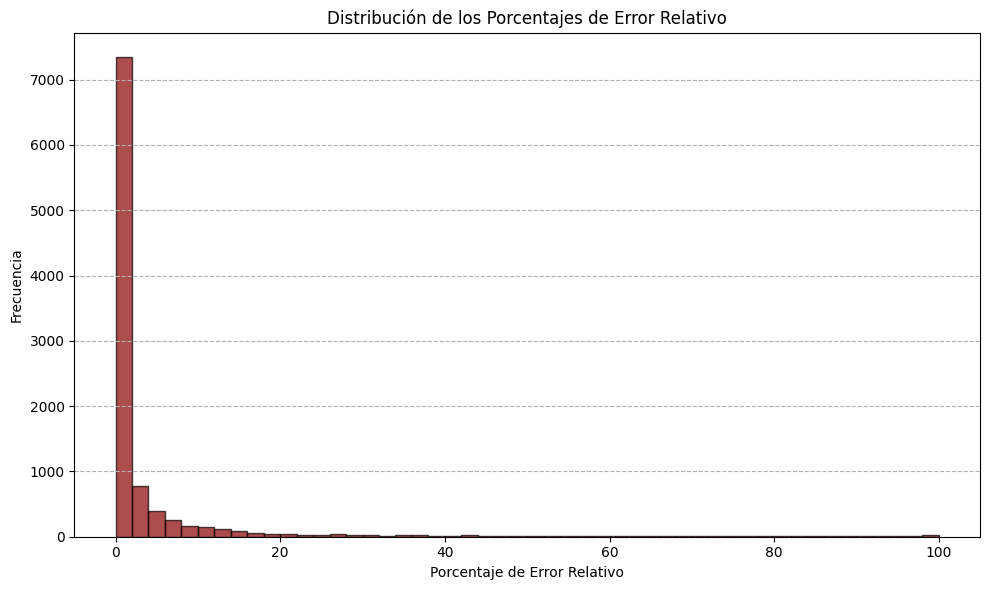

In [69]:
import matplotlib.pyplot as plt

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()